## MV analysis of the serotonine receptor HTR2A
The HTR2A receptor is a GPCR (G protein-coupled receptor) that binds to 5-hydroxytryptamine, commonly known as serotonin. This receptor participates in mood regulation and it is also responsible for the psychedelic effects of substances such as LSD and psilocybin (found in "magic mushrooms"). 

Malfunction of these cell membrane receptors, which are primarily found in the neurons of the brain, can lead to various mental disorders as schizophrenia (https://pubmed.ncbi.nlm.nih.gov/15083167/) or panic disorders (https://pmc.ncbi.nlm.nih.gov/articles/PMC2656878/). Hence, it is also the target of several antipsychotic drugs.

Let’s explore the missense variants (MVs) affecting this receptor:

- GPCRmd: GPCRmd is a database that provides molecular dynamics (MD) simulations of GPCRs and interactive tools to explore the dynamic behavior of these proteins. Go to GPCRmd (https://www.gpcrmd.org/) and enter "5-hydroxytryptamine receptor 2a" in the search bar.
- Find the simulation of the PDB '6A93' and click 'View' to visualize the MD

![title](../images/img1.png)


- Open the 'Genetic variants' tab and click 'On' to show all the MVs affecting the protein:


![title](../images/img2.png)


- All the information about the displayed MVs in the viewer is collected in the table. By clicking 'Download,' you can save all the table data. However, **this step is not necessary** as the file is already saved as gpcrmd_mvs.json in the /data folder.

  
![title](../images/img3.png)


#### 1. Load the json file into a python dictionary and create a pandas dataframe
Pandas is a very powerful package to work with data tables, it can load xls, csv, among other data formats. Let's import the package and load the MV data we have just seen from GPCRmd:

In [1]:
# import packages for data processing
import pandas as pd
import json

In [2]:
mvsDataFile= '../data/gpcrmd_mvs.json' # file with the MV data downloaded from GPCRmd

In [3]:
with open(mvsDataFile, 'r') as file:# Load the JSON file
    mvData = json.load(file)

htr2aData = mvData['5ht2a_human'] # Extract the values of our receptor of interest 'htr2a_human'

# Parse the dictionary to fill in the dataframe (you can ignore this block of code as it is only parsing the json file)
data = {} # fill in an auxiliar dict, key as MV id, value as a list with all the table values
cols=None
for key, value in htr2aData.items():  # iterate through the positions that have MVs
    for mvData in value: # iterate through the MVs of the position
        mvRow=[]
        if not cols:# fill in once the column name list for the dataframe
            cols=mvData.keys()
        for col, info in mvData.items():# if the value is dictionary, take only the value
            enstList=[]
            if type(info)==dict and len(info.keys())>0:
                enstList.extend(info.values())
                mvData[col]=enstList[0]
        mvRow.extend(mvData.values()) # add all the values to as a list
        data[mvData['From']+key+mvData['To']]=mvRow

mvs=pd.DataFrame(data).transpose() # load dictionary to df
mvs.columns=cols # set the columns
positions=mvs.index
positions=[int(i[1:-1]) for i in positions]
mvs['Pos']=positions
mvs=mvs[~mvs['SIFT score'].apply(lambda x: isinstance(x, dict) and not isinstance(x, float))]# do not consider MVs without SIFT score (different transcript)
mvs=mvs.sort_values(by='Pos')# sort by position of the MV

mvs.head() # show parsed data of our receptor, it is the same data we saw on GPCRmd page

,Role,totalDiseases,SIFT score,GPCRdb,Segment,PTM,diseaseTopName,Allele Count,MutationType,Disease,...,varID,UIP,Polyphen-2 score,diseaseTopScore,Modified Residue,Disulfide Bond,From,diseaseTopId,Allele Number,Pos
E6G,,,0.02,,N-term,No,,,changed,No,...,rs1418879482,0,0.08,,,,E,,,6
S12N,,,1,,N-term,No,,,similar,No,...,rs545813583,0,0,,,,S,,,12
T14I,,,0.08,,N-term,No,,,changed,No,...,rs778929461,0,0,,,,T,,,14
T14A,,,0.26,,N-term,No,,,changed,No,...,rs747855847,0,0.003,,,,T,,,14
T15M,,,0.04,,N-term,No,,,changed,No,...,rs754812239,0,0.024,,,,T,,,15


In [4]:
mvs.columns

Index(['Role', 'totalDiseases', 'SIFT score', 'GPCRdb', 'Segment', 'PTM',
       'diseaseTopName', 'Allele Count', 'MutationType', 'Disease',
       'Allele Frequency', 'To', 'Lipidation', 'Glycosylation', 'varID', 'UIP',
       'Polyphen-2 score', 'diseaseTopScore', 'Modified Residue',
       'Disulfide Bond', 'From', 'diseaseTopId', 'Allele Number', 'Pos'],
      dtype='object')

In [5]:
mvs

,Role,totalDiseases,SIFT score,GPCRdb,Segment,PTM,diseaseTopName,Allele Count,MutationType,Disease,...,varID,UIP,Polyphen-2 score,diseaseTopScore,Modified Residue,Disulfide Bond,From,diseaseTopId,Allele Number,Pos
E6G,,,0.02,,N-term,No,,,changed,No,...,rs1418879482,0,0.08,,,,E,,,6
S12N,,,1,,N-term,No,,,similar,No,...,rs545813583,0,0,,,,S,,,12
T14I,,,0.08,,N-term,No,,,changed,No,...,rs778929461,0,0,,,,T,,,14
T14A,,,0.26,,N-term,No,,,changed,No,...,rs747855847,0,0.003,,,,T,,,14
T15M,,,0.04,,N-term,No,,,changed,No,...,rs754812239,0,0.024,,,,T,,,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
N460S,,,1,,C-term,No,,,similar,No,...,rs766569786,0,0,,,,N,,,460
D462N,,,1,,C-term,No,,,changed,No,...,rs774063354,0,0,,,,D,,,462
G463R,,,0.53,,C-term,No,,,changed,No,...,rs749275325,0,0.014,,,,G,,,463
K467N,,,0.12,,C-term,No,,,changed,No,...,rs769223465,0,0,,,,K,,,467


We can see that we have all the fields displayed in the GPCRmd table, including the two impact predictive scores of SIFT and PolyPhen2.

#### 2. Add the AlphaMissense predicitons
We can also get the AlphaMissense predicions for all these MVs and add them as a new column. To do so, we will use Alphafold's website https://alphafold.ebi.ac.uk/. Search the human HTR2A protein (P28223), 'Annotations' tab and download AlphaMissense predictions for all positions with the 'Heatmap data' option and save it in /data folder.

![title](../images/img4.png)


In [6]:
# load AlphaMissense predicitons for 5HT2A into a dataframe
AMFile= '../data/AF-P28223-F1-aa-substitutions.csv' # file with the MV data downloaded from AlphaFold
am =pd.read_csv(AMFile, index_col=0) # use the first column of the file as the index to match mvs dataframe structure
am.head()

,am_pathogenicity,am_class
protein_variant,,
M1A,0.3430,Amb
M1C,0.3801,Amb
M1D,0.5871,LPath
M1E,0.3651,Amb
M1F,0.2390,LBen


This dataframe shows all the possible residue substitutions (19) for all positions, the AlphaMissense score and the classification:
- 'LBen': likely beign, score between 0.0 and 0.34
- 'Amb': ambiguous, score between 0.34 and 0.564
- 'LPath': likely pathogenic, score between 0.564 and 1.0

Now lets add the AlphaMissense predictions to the data of MVs extracted from GPCRmd as those are the ones actually found in human population.

In [7]:
mvs = mvs.join(am) # add AlphaMissense predictions to our GPCRmd dataset
mvs

,Role,totalDiseases,SIFT score,GPCRdb,Segment,PTM,diseaseTopName,Allele Count,MutationType,Disease,...,Polyphen-2 score,diseaseTopScore,Modified Residue,Disulfide Bond,From,diseaseTopId,Allele Number,Pos,am_pathogenicity,am_class
E6G,,,0.02,,N-term,No,,,changed,No,...,0.08,,,,E,,,6,0.0726,LBen
S12N,,,1,,N-term,No,,,similar,No,...,0,,,,S,,,12,0.0614,LBen
T14I,,,0.08,,N-term,No,,,changed,No,...,0,,,,T,,,14,0.0852,LBen
T14A,,,0.26,,N-term,No,,,changed,No,...,0.003,,,,T,,,14,0.0636,LBen
T15M,,,0.04,,N-term,No,,,changed,No,...,0.024,,,,T,,,15,0.0885,LBen
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
N460S,,,1,,C-term,No,,,similar,No,...,0,,,,N,,,460,0.0587,LBen
D462N,,,1,,C-term,No,,,changed,No,...,0,,,,D,,,462,0.0632,LBen
G463R,,,0.53,,C-term,No,,,changed,No,...,0.014,,,,G,,,463,0.0754,LBen
K467N,,,0.12,,C-term,No,,,changed,No,...,0,,,,K,,,467,0.1828,LBen


Now we have the predcitions of three different algorithms SIFT, PolyPhen2 and AlphaMissense, let's see if all them are in agreement.

In [8]:
# import required packages for data visualization
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap

In [9]:
# Add SIFT classification column with the benign-pathogenic thresholds
mvs['SIFT_class'] = mvs['SIFT score'].apply(lambda x: 'LBen' if float(x) > 0.05 else 'LPath')

# Add Polyphen2_classification
mvs['Polyphen2_class'] = mvs['Polyphen-2 score'].apply(lambda x: 'LBen' if 0.0 <= float(x) <= 0.446 else 'LPath')

# Create a heatmap
mapping = {'LBen': 0, 'Amb': 0.5, 'LPath': 1}
heatmap_data = mvs[['SIFT_class', 'Polyphen2_class', 'am_class']].apply(lambda col: col.map(mapping)).T

# Custom colormap
custom_cmap = ListedColormap(['lightblue', 'lightgray','lightpink'])

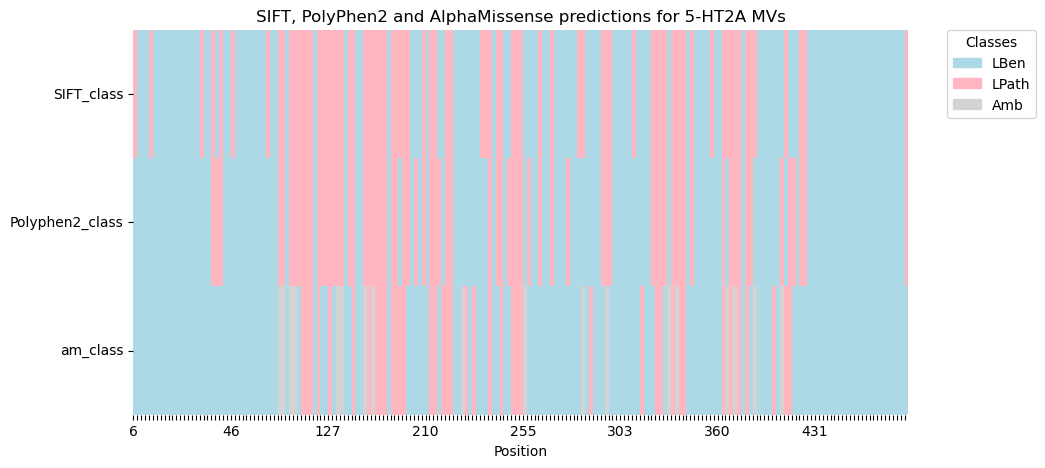

In [10]:
# Plot the heatmap
plt.figure(figsize=(10, 5))
sns.heatmap(
    heatmap_data,
    cmap=custom_cmap,
    cbar=False,
    xticklabels=mvs.index,
    yticklabels=heatmap_data.index
)

# Add legend with the categorical tags
legend_labels = ['LBen', 'LPath', 'Amb']
legend_colors = ['lightblue', 'lightpink', 'lightgray']
handles = [Patch(color=color, label=label) for color, label in zip(legend_colors, legend_labels)]
plt.legend(
    handles=handles,
    title="Classes",
    loc="upper left",
    bbox_to_anchor=(1.05, 1),
    borderaxespad=0
)

# Modify x-axis labels to show every 25th index
plt.xticks(ticks=range(len(mvs.index)), labels=[idx if i % 25 == 0 else '' for i, idx in enumerate( mvs['Pos'])], rotation=0)
plt.xlabel('Position')

plt.yticks(rotation=0) # Tilt y-axis labels

plt.title("SIFT, PolyPhen2 and AlphaMissense predictions for 5-HT2A MVs")
plt.show()

We can see that in a lot of cases there is not agreement between all three predictors (not all the rows have the same color). 

- Why do you think this is happening?
- Which prediction would you belive?

#### 3. Visualization of the structural and dynamic impact of a MV
Now we want to see an example of how one of these MVs impact the receptor functionality. Among the listed MVs of this receptor we can find a MV which is affecting affecting an important residue, a cysteine in position 227 (C227). 

In [11]:
indexes_with_227 = list(mvs[mvs['Pos'] == 227].index) # look for MVs affecting position 227
print(f'MV affecting position 227 of the receptor: {indexes_with_227}')

# get the predictions for C227Y
siftPred=mvs.loc[indexes_with_227[0], 'SIFT_class']
pp2pred=mvs.loc[indexes_with_227[0], 'Polyphen2_class']
ampred=mvs.loc[indexes_with_227[0], 'am_class']
print(f'Pathogenic predicitons of SIFT, PolyPhen2 and AlphaMissense: {siftPred}, {pp2pred}, {ampred}')

MV affecting position 227 of the receptor: ['C227Y']
Pathogenic predicitons of SIFT, PolyPhen2 and AlphaMissense: LPath, LPath, LPath


##### Why is this an important residue? 

We see that all three predictors consider this MV pathogenic. This cysteine is located in an extracellular loop involved in the ligand-binding process. It forms a disulfide bridge (S - S interaction) with another cysteine at position 148. This is an important interaction, highly conserved in GPCRs, that anchors the extracellular loop to a transmembrane helix.

To analyze the behaviour of this interaction in the WT receptor and in the receptor with the C227Y MV, we will visualize both MDs in VMD. 

Launch VMD and open both MDs:

1. Load the WT MD:
- First, load the psf file (structure file): File > "New molecule..." and browse the file /data/structureWT.psf.
- Then, load the dcd (trajectory file) 'on top' of the structure file: Right click on "structureWT.psf" and "Load Data Into Molecule..." browse /data/WT_traj.dcd.


2. Load MD of the system with C227Y:
- Do the same for structureC227Y.psf and C227Y_traj.dcd

![title](../images/img5.png)



Now edit the reprentations, open Graphics > Representations and in both WT and C227Y (by switching Selected Molecule option) create the following representations:
- "protein"  with Drawing Method -> NewCartoon
- "resname ZOT" Drawing Method -> Licorize
- "resid 227" Drawing Method -> Licorize
- "resid 148" Drawing Method -> Licorize

![title](../images/img5_1.png)

Like this, you will see both proteins, the WT and the system with the C227Y MV, in complex with a ligand and also the residues 148 and 227.

![title](../images/img6.png)

Play both MDs to check the differences between residues 148 and 227 and their interaction.

*Note:* you can reset the view by pressing "Alt + =". This will center again the view on protein with the 'T' (top) active in the Main panel. To swich it to another molecule double click on the 'T' column of the desired molecule.

#### 4. Quantify the impact
Let's put numbers to the differences we observe. Compute the distance between both residues 227-148 in WT simulation and C227Y:
- Active the 'T' in WT_receptor in the main panel: the 'T' refers to 'top' and indicates the active molecule (to swich it to another molecule double click on the 'T' column of the desired molecule).
- Now, click the visualization screen and then click button '2', this will enable the computation of distance tool. To make it work you  need to click the two atoms you want to know their distance: click the S atom of both cysteines, S of C148 (in yellow) and S of C227. After that, you will see the distance between both atoms displayed in the current frame as a dashed line:

![title](../images/img7.png)


However, what we want are the distances between the residues during the whole MD - not just in one frame - so let's compute it:

- In the Main panel open 'Graphics'>'Labels'. After that, in the Labels panel select the option 'Bonds'. Select the bond between cysteines.


![title](../images/img8.png)


- Click 'Graph...' button to previsualize the data, then 'Save...' to save the data as /results/disulfide_bond_WT.csv

Repeat the same with the C227Y system (using the oxigen atom of Y227 this time, in red) and save the data as /results/disulfide_bond_C227Y.csv

Load both csv files to see the data that we have:

In [12]:
# load distance files
WTDistanceFile= '../results/disulfide_bond_WT.csv'
C227YDistanceFile= '../results/disulfide_bond_C227Y.csv'
wtData =pd.read_csv(WTDistanceFile, index_col=0, delimiter='\t') # use the first column (frame values) of the file as the index
wtData.columns = ['Distance_WT']
C227YData =pd.read_csv(C227YDistanceFile, index_col=0, delimiter='\t') 
C227YData.columns = ['Distance_C227Y']
wtData.head()

,Distance_WT
0,
1,1.962968
2,2.039833
3,2.026702
4,2.021725
5,2.034851


In both dataframes we see the index as the frame number and a column with the distances between the atoms in angstroms. Merge both dataframes and plot the data to see a possible impact in the perturbed disulfide bridge.

In [13]:
distance=wtData.join(C227YData) 
distance.head()

,Distance_WT,Distance_C227Y
0,,
1,1.962968,6.570759
2,2.039833,7.344744
3,2.026702,6.946292
4,2.021725,8.370181
5,2.034851,6.811512


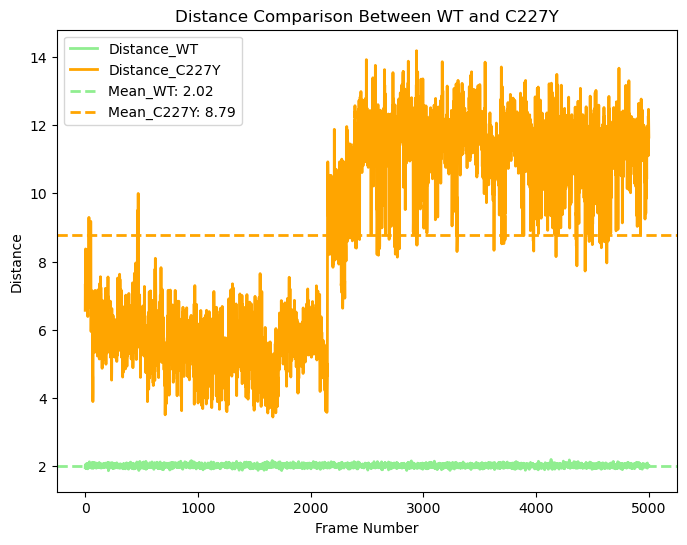

In [14]:
# Calculate the mean values for both distances WT and C227Y
mean_WT = distance['Distance_WT'].mean()
mean_C227Y = distance['Distance_C227Y'].mean()

# Plot the distances
plt.figure(figsize=(8, 6))
plt.plot(distance.index, distance['Distance_WT'], label='Distance_WT', color='lightgreen', lw=2)
plt.plot(distance.index, distance['Distance_C227Y'], label='Distance_C227Y', color='orange', lw=2)

# Plot dashed lines for the mean values
plt.axhline(y=mean_WT, color='lightgreen', linestyle='--', lw=2, label=f'Mean_WT: {mean_WT:.2f}')
plt.axhline(y=mean_C227Y, color='orange', linestyle='--', lw=2, label=f'Mean_C227Y: {mean_C227Y:.2f}')

# Add labels and title
plt.xlabel('Frame Number')
plt.ylabel('Distance')
plt.title('Distance Comparison Between WT and C227Y')

plt.legend() # Display the legend

plt.show() # Show the plot

- What can you conclude? Were the predictors right?
- Which implications do you think this MV will have in protein functionality? 

Look at the impact in ECL2 stability:


![title](../images/img9.png)


#### Conclusion

Some diseases can result from a wide range of genetic variants. For example, over 2,000 known mutations can lead to cystic fibrosis, and patients with different types of genetic variants often require tailored treatments - the possible protein 'fails' can be very diverse. Therefore, understanding how each variant affects functionality is crucial for providing the best treatment.

In this particular case, now that you understand how the C227Y MV impacts receptor functionality, do you have ideas on how to restore receptor function using a drug for individuals with this specific MV?

In this case, the approach would involve using a ligand that binds near the original disulfide bridge, stabilizing the distance between the ECL2 and TM3. These types of ligands are known as "pharmacological chaperones."


Check the full study of the funtional impact of the mutation:
https://www.sciencedirect.com/science/article/abs/pii/S0014299917305940